# Proyecto 1 · Variante A — Pareja 1: datos, validación y KNN base

## Alcance de esta entrega

Este notebook implementa el bloque asignado a **pareja 1**: carga y caracterización de `load_digits()`, normalización fija de píxeles, partición estratificada desarrollo/prueba, persistencia de índices y folds, y evaluación del modelo base KNN mediante validación cruzada repetida. Se informan métricas de entrenamiento y validación, dimensiones, tiempos de predicción y variabilidad descriptiva.

La pregunta experimental integrada es si PCA puede reducir la dimensión y el costo de predicción de KNN conservando su F1 macro. Las 64 intensidades de una imagen 8×8 son la representación inicial; parte de esa dimensión puede ser redundante o poco informativa, hipótesis que pareja 2 evaluará sin asumir que PCA necesariamente mejora el clasificador.

La prueba se mantiene reservada: aquí **no se ajusta, compara ni selecciona** ningún modelo usando sus predicciones. La evaluación final en test corresponde a pareja 3. La comparación PCA+KNN y las diferencias pareadas completas se incorporan cuando pareja 2 produzca sus resultados sobre estos mismos folds.

> Alcance estadístico: análisis descriptivo. Las medias y desviaciones estándar no constituyen una prueba de hipótesis ni evidencian significancia, equivalencia o superioridad general.

In [7]:
from pathlib import Path
import json
import math
import platform
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Buscar la raíz desde cwd permite ejecutar el notebook desde la raíz o una subcarpeta.
PROJECT_RELATIVE_PATH = Path("practicas") / "p_03"
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / PROJECT_RELATIVE_PATH / "readme.md").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Ejecuta el notebook desde una carpeta dentro del repositorio."
    )

PROJECT_DIR = PROJECT_ROOT / PROJECT_RELATIVE_PATH
REPORT_DIR = PROJECT_DIR / "report"
PLOTS_DIR = REPORT_DIR / "plots"
RESULTS_DIR = PROJECT_DIR / "results" / "pareja_1"
for output_dir in (REPORT_DIR, PLOTS_DIR, RESULTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

# Parámetros fijados por el protocolo; no se optimizan mirando el conjunto de prueba.
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_REPEATS = 3
K_VALUES = (1, 3, 5, 7)
PIXEL_INTENSITY_MAX = 16.0  # Máximo definido por la escala conocida de load_digits: [0, 16].
N_TIMING_MEASUREMENTS = 5
SELECTION_TOLERANCE = 0.005

# Estética clara para que etiquetas, rejilla y colores sigan siendo legibles al proyectar.
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("colorblind")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 200,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#263238",
        "text.color": "#263238",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

print(f"Python: {platform.python_version()}")
print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print(f"Directorio de trabajo: {Path.cwd()}")
print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Resultados de pareja 1: {RESULTS_DIR}")

Python: 3.13.15
scikit-learn: 1.9.0
numpy: 2.5.1
pandas: 3.0.5
matplotlib: 3.11.0
seaborn: 0.13.2
Directorio de trabajo: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/code
Raíz del proyecto: /home/ldan/Documents/0_uni/5to_sem/ml_team
Resultados de pareja 1: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1


## 1. Datos, atributos y escala de los píxeles

`load_digits()` contiene imágenes en escala de grises de **8 × 8** píxeles. Al aplanar cada imagen se obtiene un vector de **64 atributos**, uno por píxel, y la etiqueta es un dígito entre 0 y 9. El código consulta las dimensiones, tipos y rangos reales en ejecución; no copia ejemplos ni filas a mano.

La intensidad observada está en el rango conocido `[0, 16]`. Se aplica la transformación fija

$$
 x_{ij}^{(norm)} = \frac{x_{ij}}{16},
$$

donde `i` identifica una imagen y `j` uno de sus píxeles. Así cada atributo queda en `[0, 1]`. El divisor es una propiedad conocida de la escala del conjunto, no un parámetro estimado con los datos; no se ajusta un escalador usando validación o prueba. La división por una constante positiva preserva el orden relativo de las intensidades y expresa las distancias en una escala común.

La cuadrícula de ejemplos muestra una imagen por clase para relacionar los 64 valores con el problema de clasificación. El gráfico de conteos es una comprobación descriptiva de la distribución de clases.

X_raw: dimensiones=(1797, 64), tipo=float64, rango=[0.0, 16.0]
X normalizada: dimensiones=(1797, 64), tipo=float64, rango=[0.000, 1.000]
y: dimensiones=(1797,), tipo=int64, clases=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
images: dimensiones=(1797, 8, 8), tipo=float64
Número de observaciones: 1,797; atributos por observación: 64


,dígito,n,proporción
0,0,178,9.9%
1,1,182,10.1%
2,2,177,9.8%
3,3,183,10.2%
4,4,181,10.1%
5,5,182,10.1%
6,6,181,10.1%
7,7,179,10.0%
8,8,174,9.7%
9,9,180,10.0%


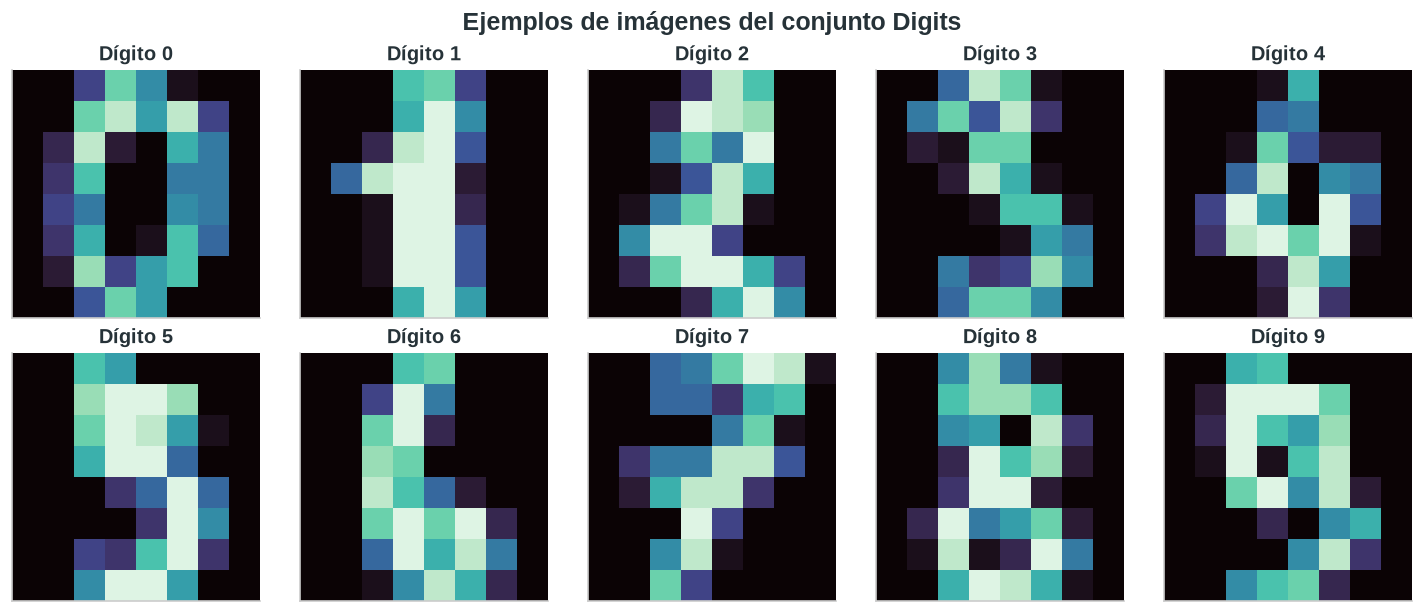

In [8]:
digits = load_digits()
X_raw = np.asarray(digits.data)
y = np.asarray(digits.target)
images = np.asarray(digits.images)

# Validar que la estructura del dataset corresponde a imágenes 8x8 aplanadas.
if X_raw.ndim != 2 or images.ndim != 3 or images.shape[1:] != (8, 8):
    raise ValueError(f"Estructura inesperada: data={X_raw.shape}, images={images.shape}")
if X_raw.shape[0] != y.shape[0] or X_raw.shape[0] != images.shape[0]:
    raise ValueError("El número de imágenes, vectores y etiquetas no coincide.")
if float(np.min(X_raw)) < 0 or float(np.max(X_raw)) > PIXEL_INTENSITY_MAX:
    raise ValueError("Las intensidades no cumplen el rango esperado [0, 16].")

# Normalización determinista con la escala fija documentada, sin estimar parámetros.
X = X_raw.astype(np.float64, copy=False) / PIXEL_INTENSITY_MAX
class_values, class_counts = np.unique(y, return_counts=True)

print(f"X_raw: dimensiones={X_raw.shape}, tipo={X_raw.dtype}, rango=[{X_raw.min()}, {X_raw.max()}]")
print(f"X normalizada: dimensiones={X.shape}, tipo={X.dtype}, rango=[{X.min():.3f}, {X.max():.3f}]")
print(f"y: dimensiones={y.shape}, tipo={y.dtype}, clases={class_values.tolist()}")
print(f"images: dimensiones={images.shape}, tipo={images.dtype}")
print(f"Número de observaciones: {X.shape[0]:,}; atributos por observación: {X.shape[1]}")

display(
    pd.DataFrame(
        {
            "dígito": class_values,
            "n": class_counts,
            "proporción": class_counts / class_counts.sum(),
        }
    ).style.format({"proporción": "{:.1%}"})
)

# Una observación representativa por clase: la primera que aparece en el dataset.
fig, axes = plt.subplots(2, 5, figsize=(12, 5), constrained_layout=True)
for ax, digit in zip(axes.flat, class_values):
    sample_position = int(np.flatnonzero(y == digit)[0])
    ax.imshow(images[sample_position], cmap="mako", vmin=0, vmax=PIXEL_INTENSITY_MAX)
    ax.set_title(f"Dígito {digit}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Ejemplos de imágenes del conjunto Digits", fontsize=15, fontweight="bold")
fig.savefig(PLOTS_DIR / "digits_ejemplos.png", bbox_inches="tight")
plt.show()

## 2. Partición desarrollo/prueba y validación cruzada

Se reserva una partición estratificada del 20 % como **prueba final** y el 80 % restante como desarrollo. Para mantener los índices originales, primero se separan posiciones de `X` y `y` con `train_test_split`; se usa `stratify=y` para conservar aproximadamente la proporción de las diez clases en ambas partes.

En desarrollo se aplica `RepeatedStratifiedKFold` con 5 pliegues y 3 repeticiones: cada observación de desarrollo aparece una vez en validación por repetición, para un total de $5\times3=15$ evaluaciones. La semilla raíz 42 controla el generador repetido completo. Los índices concretos de cada pliegue se guardan, y son la referencia exacta para que pareja 2 evalúe PCA+KNN sin regenerar divisiones.

En cada fold, el modelo se ajusta solo con `X_train_fold`; las métricas de validación solo se calculan sobre `X_validation_fold`. El conjunto de prueba permanece fuera de la selección. Los tamaños esperados se calculan desde el tamaño real del dataset (incluyendo el redondeo de `test_size`), y se imprimen dimensiones y conteos por clase para comprobar la partición.

X desarrollo: dimensiones=(1437, 64), tipo=float64
X prueba reservada: dimensiones=(360, 64), tipo=float64
y desarrollo: dimensiones=(1437,), tipo=int64
y prueba reservada: dimensiones=(360,), tipo=int64
Observaciones: total=1,797; desarrollo=1,437; prueba=360
Índices y folds guardados en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/indices.json


,dígito,Desarrollo,Prueba reservada
0,0,142,36
1,1,146,36
2,2,142,35
3,3,146,37
4,4,145,36
5,5,145,37
6,6,145,36
7,7,143,36
8,8,139,35
9,9,144,36


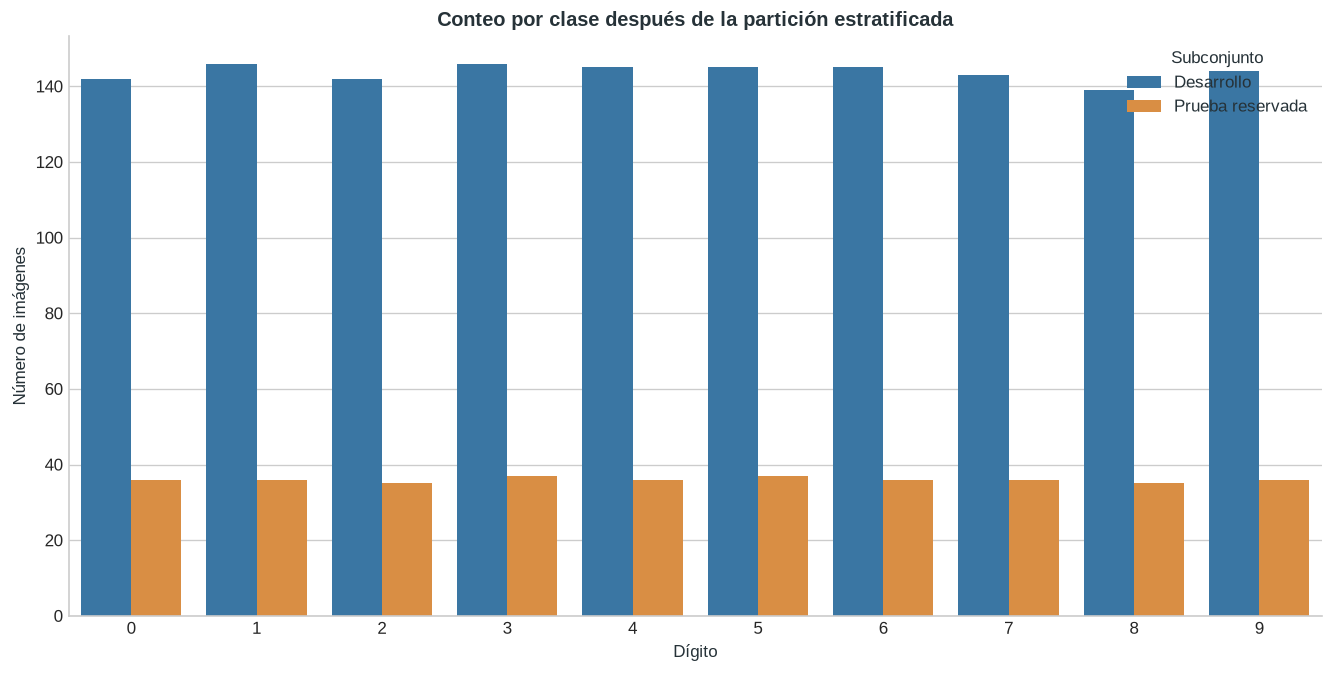

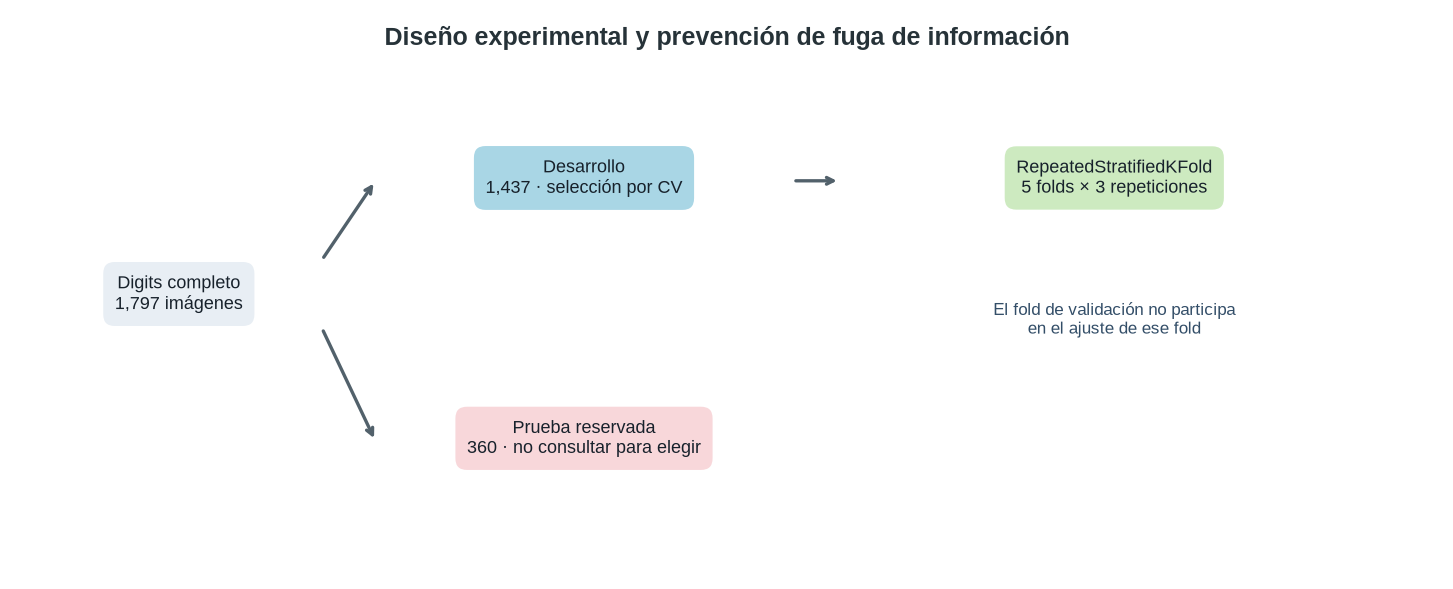

In [9]:
sample_indices = np.arange(y.size)
development_indices, test_indices = train_test_split(
    sample_indices,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)
X_development, y_development = X[development_indices], y[development_indices]
X_test_reserved, y_test_reserved = X[test_indices], y[test_indices]

expected_test_size = math.ceil(y.size * TEST_SIZE)
if test_indices.size != expected_test_size:
    raise AssertionError(
        f"Tamaño de prueba inesperado: {test_indices.size}; esperado por el protocolo: {expected_test_size}."
    )
if development_indices.size + test_indices.size != y.size:
    raise AssertionError("La partición no conserva todas las observaciones.")

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE,
)
cv_splits = list(cv.split(X_development, y_development))
if len(cv_splits) != N_SPLITS * N_REPEATS:
    raise AssertionError("La validación no produjo el número esperado de folds.")

fold_records = []
for fold_number, (train_positions, validation_positions) in enumerate(cv_splits):
    repetition = fold_number // N_SPLITS + 1
    fold_in_repetition = fold_number % N_SPLITS + 1
    fold_records.append(
        {
            "fold_id": f"rep-{repetition}-fold-{fold_in_repetition}",
            "repetition": repetition,
            "fold_in_repetition": fold_in_repetition,
            "train_development_positions": train_positions.tolist(),
            "validation_development_positions": validation_positions.tolist(),
            "train_sample_indices": development_indices[train_positions].tolist(),
            "validation_sample_indices": development_indices[validation_positions].tolist(),
        }
    )

indices_artifact = {
    "dataset": "sklearn.datasets.load_digits",
    "dataset_observations": int(y.size),
    "protocol": {
        "test_size": TEST_SIZE,
        "stratified": True,
        "random_state": RANDOM_STATE,
        "cv_class": "RepeatedStratifiedKFold",
        "n_splits": N_SPLITS,
        "n_repeats": N_REPEATS,
        "cv_random_state": RANDOM_STATE,
        "repetition_seed_records": [
            {"repetition": repetition, "root_random_state": RANDOM_STATE, "independent_seed": False}
            for repetition in range(1, N_REPEATS + 1)
        ],
        "seed_note": (
            "La semilla 42 inicializa el generador de RepeatedStratifiedKFold para las tres repeticiones; "
            "los índices realizados se persisten abajo como referencia exacta."
        ),
    },
    "development_sample_indices": development_indices.tolist(),
    "test_sample_indices": test_indices.tolist(),
    "folds": fold_records,
}
INDICES_PATH = RESULTS_DIR / "indices.json"
INDICES_PATH.write_text(json.dumps(indices_artifact, indent=2), encoding="utf-8")

print(f"X desarrollo: dimensiones={X_development.shape}, tipo={X_development.dtype}")
print(f"X prueba reservada: dimensiones={X_test_reserved.shape}, tipo={X_test_reserved.dtype}")
print(f"y desarrollo: dimensiones={y_development.shape}, tipo={y_development.dtype}")
print(f"y prueba reservada: dimensiones={y_test_reserved.shape}, tipo={y_test_reserved.dtype}")
print(f"Observaciones: total={y.size:,}; desarrollo={y_development.size:,}; prueba={y_test_reserved.size:,}")
print(f"Índices y folds guardados en: {INDICES_PATH}")

# Verificar y documentar los conteos de clase; la prueba solo se describe, no se usa para elegir.
class_distribution = pd.DataFrame({"dígito": class_values})
for partition_name, labels in (("Desarrollo", y_development), ("Prueba reservada", y_test_reserved)):
    counts = pd.Series(labels).value_counts().reindex(class_values, fill_value=0)
    class_distribution[partition_name] = counts.to_numpy()
display(class_distribution)

class_distribution_long = class_distribution.melt(
    id_vars="dígito", var_name="Partición", value_name="Observaciones"
)
fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
sns.barplot(
    data=class_distribution_long,
    x="dígito",
    y="Observaciones",
    hue="Partición",
    palette=["#2878B5", "#F28E2B"],
    ax=ax,
)
ax.set(title="Conteo por clase después de la partición estratificada", xlabel="Dígito", ylabel="Número de imágenes")
ax.legend(title="Subconjunto", frameon=False)
fig.savefig(PLOTS_DIR / "conteo_clases_split.png", bbox_inches="tight")
plt.show()

# Diagrama del protocolo, no una evaluación adicional: prueba queda aislada de la CV.
fig, ax = plt.subplots(figsize=(12, 4.8), constrained_layout=True)
ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.axis("off")

def add_box(x, y, width, height, text, color, fontsize=11):
    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        color="#17212B",
        bbox={"boxstyle": "round,pad=0.7", "facecolor": color, "edgecolor": "#FFFFFF", "linewidth": 1.5},
    )

add_box(0.3, 1.8, 2.2, 1.4, f"Digits completo\n{y.size:,} imágenes", "#E8EEF4")
add_box(3.2, 2.9, 3.2, 1.25, f"Desarrollo\n{y_development.size:,} · selección por CV", "#A9D6E5")
add_box(7.1, 2.9, 4.3, 1.25, f"RepeatedStratifiedKFold\n{N_SPLITS} folds × {N_REPEATS} repeticiones", "#CDEAC0")
add_box(3.2, 0.65, 3.2, 1.15, f"Prueba reservada\n{y_test_reserved.size:,} · no consultar para elegir", "#F8D7DA")
ax.annotate("", xy=(3.05, 3.5), xytext=(2.6, 2.8), arrowprops={"arrowstyle": "->", "lw": 2, "color": "#52616B"})
ax.annotate("", xy=(3.05, 1.2), xytext=(2.6, 2.2), arrowprops={"arrowstyle": "->", "lw": 2, "color": "#52616B"})
ax.annotate("", xy=(6.95, 3.5), xytext=(6.55, 3.5), arrowprops={"arrowstyle": "->", "lw": 2, "color": "#52616B"})
ax.text(6, 4.7, "Diseño experimental y prevención de fuga de información", ha="center", fontsize=15, fontweight="bold")
ax.text(9.25, 2.15, "El fold de validación no participa\nen el ajuste de ese fold", ha="center", fontsize=10, color="#334E68")
fig.savefig(PLOTS_DIR / "flujo_validacion.png", bbox_inches="tight")
plt.show()

## 3. Algoritmo base: K-Nearest Neighbors

KNN es un método basado en instancias: para una observación nueva $x$, localiza los $k$ puntos de entrenamiento más cercanos y asigna la clase más votada. La distancia euclidiana usada aquí es

$$
 d(x,z)=\sqrt{\sum_{j=1}^{D}(x_j-z_j)^2},
$$

donde $D=64$ es el número de píxeles. `metric="minkowski", p=2` representa esta distancia; `weights="uniform"` asigna un voto a cada vecino; `algorithm="brute"` calcula las distancias de forma uniforme y es la opción exigida para que pareja 2 compare con la misma estrategia computacional. Se prueban los cuatro valores `k ∈ {1, 3, 5, 7}` indicados por el protocolo.

Para cada fold se calcula F1 macro y exactitud, tanto sobre el propio entrenamiento como sobre validación. F1 macro da el mismo peso a cada clase:

$$
F1_c=\frac{2\,P_cR_c}{P_c+R_c},\qquad
F1_{macro}=\frac{1}{C}\sum_{c=1}^{C}F1_c,
$$

con precisión $P_c=TP_c/(TP_c+FP_c)$, recall $R_c=TP_c/(TP_c+FN_c)$ y $C=10$ clases. La exactitud es el número de predicciones correctas dividido por el total. La métrica principal es F1 macro; exactitud es secundaria.

El tiempo de inferencia se mide solo en el bloque de validación: una predicción de calentamiento descartada y luego cinco mediciones con `perf_counter`; la **mediana** de esas cinco es el tiempo de ese fold. Las mediciones repetidas de cronómetro no son folds independientes. El ajuste y el tiempo de entrenamiento no forman parte de esta medida. F1 de entrenamiento puede ser optimista (especialmente con `k=1`, porque cada punto es su propio vecino al predecir el train), por lo que la comparación de generalización se basa en validación.

In [10]:
def measure_prediction_time_ms(estimator, X_batch, n_measurements=N_TIMING_MEASUREMENTS):
    """Retorna las mediciones de predict en ms, tras una llamada de calentamiento descartada."""
    estimator.predict(X_batch)  # Calentamiento: no se incluye en el resumen del fold.
    measured_ms = []
    for _ in range(n_measurements):
        start = time.perf_counter()
        estimator.predict(X_batch)
        measured_ms.append((time.perf_counter() - start) * 1_000)
    return measured_ms

fold_metric_rows = []
for fold_number, ((train_positions, validation_positions), fold_info) in enumerate(
    zip(cv_splits, fold_records), start=1
):
    X_train_fold = X_development[train_positions]
    y_train_fold = y_development[train_positions]
    X_validation_fold = X_development[validation_positions]
    y_validation_fold = y_development[validation_positions]

    for k in K_VALUES:
        # Pipeline mantiene una interfaz homogénea con la futura propuesta PCA + KNN.
        model = Pipeline(
            [
                (
                    "knn",
                    KNeighborsClassifier(
                        n_neighbors=k,
                        metric="minkowski",
                        p=2,
                        weights="uniform",
                        algorithm="brute",
                    ),
                )
            ]
        )
        model.fit(X_train_fold, y_train_fold)
        train_predictions = model.predict(X_train_fold)
        validation_predictions = model.predict(X_validation_fold)
        timing_measurements_ms = measure_prediction_time_ms(model, X_validation_fold)

        fold_metric_rows.append(
            {
                "fold_id": fold_info["fold_id"],
                "repetition": fold_info["repetition"],
                "fold_in_repetition": fold_info["fold_in_repetition"],
                "family": "base",
                "k": k,
                "n_features": X_train_fold.shape[1],
                "n_train": y_train_fold.size,
                "n_validation": y_validation_fold.size,
                "f1_macro_train": f1_score(y_train_fold, train_predictions, average="macro", zero_division=0),
                "accuracy_train": accuracy_score(y_train_fold, train_predictions),
                "f1_macro_validation": f1_score(
                    y_validation_fold, validation_predictions, average="macro", zero_division=0
                ),
                "accuracy_validation": accuracy_score(y_validation_fold, validation_predictions),
                "prediction_ms_median": float(np.median(timing_measurements_ms)),
                **{
                    f"prediction_ms_measurement_{measurement_number}": timing
                    for measurement_number, timing in enumerate(timing_measurements_ms, start=1)
                },
            }
        )

fold_metrics = pd.DataFrame(fold_metric_rows)
if fold_metrics.shape[0] != len(cv_splits) * len(K_VALUES):
    raise AssertionError("No se generó una fila por configuración y fold.")
FOLD_METRICS_PATH = RESULTS_DIR / "base_fold_metrics.csv"
fold_metrics.to_csv(FOLD_METRICS_PATH, index=False)
print(f"Evaluaciones registradas: {len(fold_metrics)} (= {len(cv_splits)} folds × {len(K_VALUES)} valores de k)")
print(f"Dimensión por fold: {sorted(fold_metrics['n_features'].unique().tolist())}")
print(f"Métricas por fold guardadas en: {FOLD_METRICS_PATH}")
display(fold_metrics.head(8).style.format(precision=4))

Evaluaciones registradas: 60 (= 15 folds × 4 valores de k)
Dimensión por fold: [64]
Métricas por fold guardadas en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/base_fold_metrics.csv


,fold_id,repetition,fold_in_repetition,family,k,n_features,n_train,n_validation,f1_macro_train,accuracy_train,f1_macro_validation,accuracy_validation,prediction_ms_median,prediction_ms_measurement_1,prediction_ms_measurement_2,prediction_ms_measurement_3,prediction_ms_measurement_4,prediction_ms_measurement_5
0,rep-1-fold-1,1,1,base,1,64,1149,288,1.0000,1.0000,0.9828,0.9826,1.7187,1.4245,1.9296,2.3512,1.7187,1.3982
1,rep-1-fold-1,1,1,base,3,64,1149,288,0.9956,0.9956,0.9828,0.9826,1.7401,1.6875,1.8311,1.7401,1.7514,1.5976
2,rep-1-fold-1,1,1,base,5,64,1149,288,0.9913,0.9913,0.9896,0.9896,1.4788,3.1471,1.6435,1.4788,1.4067,1.4190
3,rep-1-fold-1,1,1,base,7,64,1149,288,0.9895,0.9896,0.9825,0.9826,1.5650,1.5861,1.5889,1.5522,1.5650,1.5422
4,rep-1-fold-2,1,2,base,1,64,1149,288,1.0000,1.0000,0.9964,0.9965,1.5421,1.5421,1.6374,1.4321,1.5589,1.4442
5,rep-1-fold-2,1,2,base,3,64,1149,288,0.9930,0.9930,0.9964,0.9965,1.5266,1.4226,2.9300,1.5370,1.3652,1.5266
6,rep-1-fold-2,1,2,base,5,64,1149,288,0.9904,0.9904,0.9964,0.9965,1.4733,1.4733,1.5172,1.4360,1.4240,2.0870
7,rep-1-fold-2,1,2,base,7,64,1149,288,0.9887,0.9887,0.9860,0.9861,1.3070,1.2001,1.2676,1.9653,1.3070,1.6231


## 4. Resumen descriptivo y regla para seleccionar la línea base

Cada configuración tiene 15 resultados, uno por fold. Para una métrica $m$, se calcula la media $\bar m=\sum_{r=1}^{15}m_r/15$ y la desviación estándar **muestral**

$$
s_m=\sqrt{\frac{\sum_{r=1}^{15}(m_r-\bar m)^2}{15-1}}.
$$

Se muestra `media ± DE` para distinguir el nivel medio del rendimiento y su dispersión entre folds; no se combinan folds, métricas o configuraciones en una única media.

La selección base sigue la regla del README: primero identificar el mayor F1 macro medio; considerar dentro del margen $\Delta=0.005$ las configuraciones cuya media queda a no más de ese umbral del máximo; para la familia base todas tienen 64 atributos, por lo que no se aplica el desempate por dimensión; entre las candidatas se prefiere menor DE de F1 y luego menor `k`. Esta regla selecciona usando validación solamente. La selección de la propuesta PCA es responsabilidad de pareja 2 y no puede completarse hasta tener sus resultados.

Para comparar posteriormente PCA+KNN con la base, la diferencia debe calcularse sobre el mismo fold:

$$
\Delta m_r = m_{r, propuesta} - m_{r, base},\qquad
\overline{\Delta m}=\frac{1}{R}\sum_{r=1}^{R}\Delta m_r.
$$

La DE muestral se calcula sobre las diferencias fold a fold, no restando medias ni mezclando folds. El helper del siguiente bloque exige emparejamiento uno-a-uno por `fold_id` y `k`. Todavía no se ejecuta porque pareja 2 aún no ha generado las métricas de propuesta; no se crean valores sustitutos.

In [11]:
def mean_sample_std(values):
    """Media y DE muestral (ddof=1) de una serie de folds."""
    return pd.Series({"mean": values.mean(), "std": values.std(ddof=1)})

metric_columns = (
    "f1_macro_train",
    "accuracy_train",
    "f1_macro_validation",
    "accuracy_validation",
    "prediction_ms_median",
)
summary_rows = []
for k, group in fold_metrics.groupby("k", sort=True):
    row = {"family": "base", "k": int(k), "n_features": int(group["n_features"].iloc[0])}
    for metric in metric_columns:
        statistics = mean_sample_std(group[metric])
        row[f"{metric}_mean"] = float(statistics["mean"])
        row[f"{metric}_std"] = float(statistics["std"])
    summary_rows.append(row)

base_summary = pd.DataFrame(summary_rows).sort_values("k").reset_index(drop=True)
max_validation_f1 = base_summary["f1_macro_validation_mean"].max()
base_candidates = base_summary.loc[
    max_validation_f1 - base_summary["f1_macro_validation_mean"] <= SELECTION_TOLERANCE
].copy()
# D=64 en todos: se omite dimensión y se desempata por DE de F1 y luego k.
base_candidates = base_candidates.sort_values(
    ["f1_macro_validation_std", "k"], ascending=[True, True], kind="stable"
)
selected_base = base_candidates.iloc[0]

SUMMARY_PATH = RESULTS_DIR / "base_summary.csv"
SELECTION_PATH = RESULTS_DIR / "selected_base.json"
base_summary.to_csv(SUMMARY_PATH, index=False)
SELECTION_PATH.write_text(
    json.dumps(
        {
            "selected_family": "base",
            "selected_k": int(selected_base["k"]),
            "n_features": int(selected_base["n_features"]),
            "selection_metric": "mean validation macro F1",
            "selection_tolerance": SELECTION_TOLERANCE,
            "tie_breaking": ["same dimension for all base models", "lower sample SD of validation macro F1", "lower k"],
            "test_used_for_selection": False,
        },
        indent=2,
    ),
    encoding="utf-8",
)

summary_display = base_summary.copy()
for metric in metric_columns:
    summary_display[metric] = summary_display.apply(
        lambda row, name=metric: f"{row[f'{name}_mean']:.4f} ± {row[f'{name}_std']:.4f}", axis=1
    )
summary_display = summary_display[["family", "k", "n_features", *metric_columns]]
display(summary_display.rename(columns={
    "family": "Familia", "k": "k", "n_features": "D",
    "f1_macro_train": "F1 macro train (media ± DE)",
    "accuracy_train": "Exactitud train (media ± DE)",
    "f1_macro_validation": "F1 macro validación (media ± DE)",
    "accuracy_validation": "Exactitud validación (media ± DE)",
    "prediction_ms_median": "Predicción validación ms (media ± DE)",
}))
print(
    f"Mejor base según validación: k={int(selected_base['k'])}, D={int(selected_base['n_features'])}, "
    f"F1 macro={selected_base['f1_macro_validation_mean']:.4f} ± "
    f"{selected_base['f1_macro_validation_std']:.4f}."
)
print(f"Candidatas dentro de Δ≤{SELECTION_TOLERANCE}: k={base_candidates['k'].astype(int).tolist()}")
print(f"Resumen guardado en: {SUMMARY_PATH}")
print(f"Selección base guardada en: {SELECTION_PATH}")


def paired_difference_summary(proposal_folds, baseline_folds):
    """Resume propuesta - base por fold, usando F1 macro y exactitud de validación."""
    join_keys = ["fold_id", "k"]
    paired_metrics = ["f1_macro_validation", "accuracy_validation"]
    required_columns = set(join_keys + paired_metrics)
    for frame_name, frame in (("proposal_folds", proposal_folds), ("baseline_folds", baseline_folds)):
        missing = required_columns.difference(frame.columns)
        if missing:
            raise ValueError(f"{frame_name} no contiene columnas requeridas: {sorted(missing)}")

    paired = proposal_folds[join_keys + paired_metrics].merge(
        baseline_folds[join_keys + paired_metrics],
        on=join_keys,
        how="outer",
        suffixes=("_proposal", "_base"),
        validate="one_to_one",
        indicator=True,
    )
    if not paired["_merge"].eq("both").all():
        raise ValueError("Propuesta y base deben contener exactamente los mismos folds y valores de k.")
    if len(paired) != N_SPLITS * N_REPEATS:
        raise ValueError(f"Se esperaban {N_SPLITS * N_REPEATS} pares; se recibieron {len(paired)}.")

    differences = paired[join_keys].copy()
    for metric in paired_metrics:
        differences[f"delta_{metric}"] = paired[f"{metric}_proposal"] - paired[f"{metric}_base"]
    difference_summary = differences.groupby("k")[[f"delta_{metric}" for metric in paired_metrics]].agg(["mean", "std"])
    return differences, difference_summary


,Familia,k,D,F1 macro train (media ± DE),Exactitud train (media ± DE),F1 macro validación (media ± DE),Exactitud validación (media ± DE),Predicción validación ms (media ± DE)
0,base,1,64,1.0000 ± 0.0000,1.0000 ± 0.0000,0.9859 ± 0.0071,0.9858 ± 0.0071,1.2390 ± 0.2554
1,base,3,64,0.9932 ± 0.0017,0.9932 ± 0.0017,0.9861 ± 0.0057,0.9861 ± 0.0057,1.4274 ± 0.2851
2,base,5,64,0.9908 ± 0.0018,0.9908 ± 0.0019,0.9840 ± 0.0053,0.9840 ± 0.0054,1.5086 ± 0.2242
3,base,7,64,0.9887 ± 0.0012,0.9887 ± 0.0012,0.9826 ± 0.0047,0.9826 ± 0.0047,1.5187 ± 0.1987


Mejor base según validación: k=7, D=64, F1 macro=0.9826 ± 0.0047.
Candidatas dentro de Δ≤0.005: k=[7, 5, 3, 1]
Resumen guardado en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/base_summary.csv
Selección base guardada en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/selected_base.json


## 5. Figuras de resultados de la línea base

El gráfico de la izquierda compara el F1 macro de validación para cada `k`; el de la derecha muestra la exactitud secundaria. Los puntos son medias de 15 folds y las barras representan **±1 desviación estándar muestral** entre folds, no intervalos de confianza. Las series se mantienen separadas porque sus escalas e interpretación son distintas.

La figura de tiempo presenta la media y DE de las 15 medianas por fold; cada mediana proviene de cinco cronometrajes tras un calentamiento descartado. El cronometraje es orientativo y depende del equipo y su carga. No se usa para seleccionar el modelo base. Todos los archivos se escriben debajo de `practicas/p_03/report/plots/` para incorporarlos al informe.

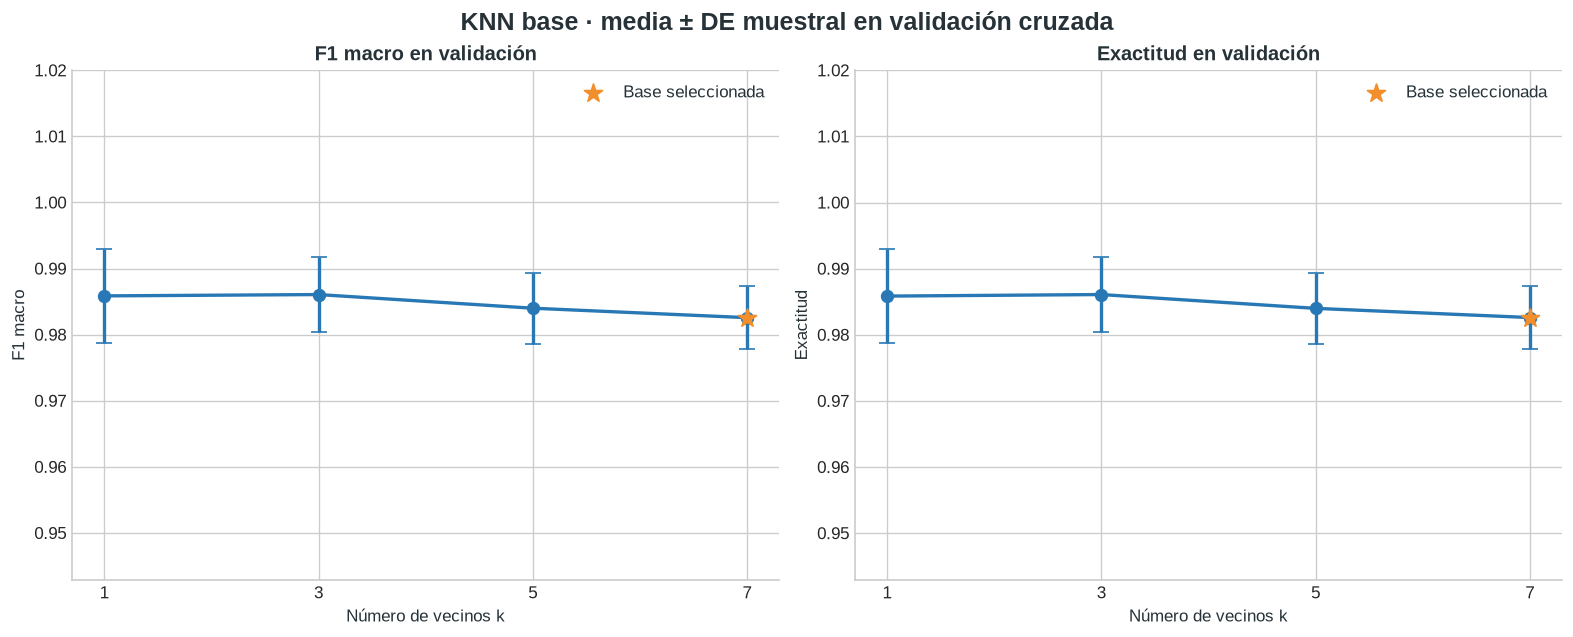

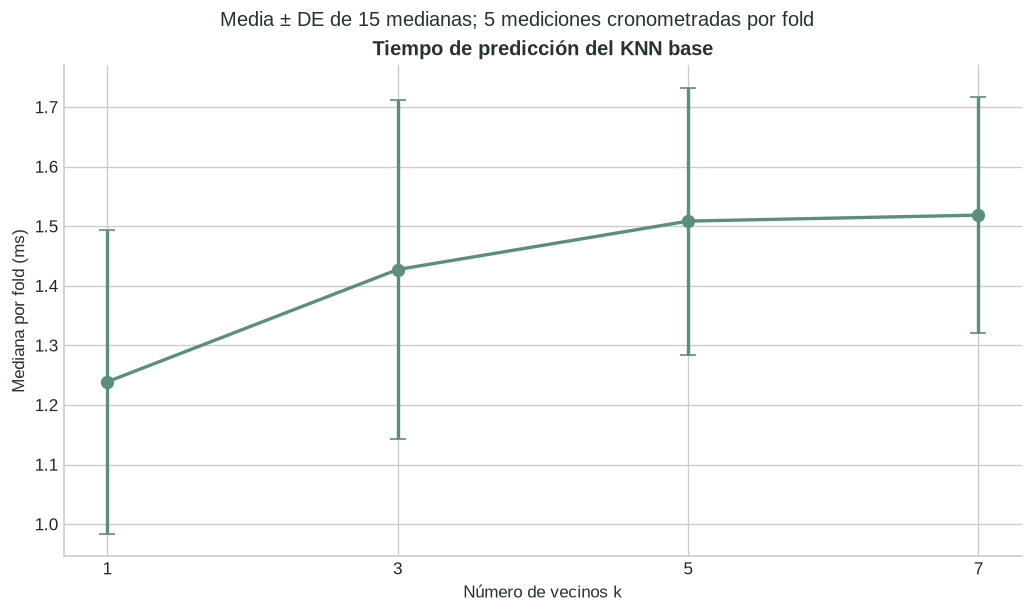

Figuras guardadas:
- report/plots/conteo_clases_split.png (61,305 bytes)
- report/plots/digits_ejemplos.png (40,748 bytes)
- report/plots/flujo_validacion.png (94,520 bytes)
- report/plots/knn_base_metricas_cv.png (105,302 bytes)
- report/plots/knn_base_tiempos_cv.png (65,026 bytes)


In [12]:
k_axis = base_summary["k"].to_numpy()
selected_k = int(selected_base["k"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
plot_specs = (
    ("f1_macro_validation", "F1 macro en validación", "F1 macro"),
    ("accuracy_validation", "Exactitud en validación", "Exactitud"),
)
for ax, (metric, title, ylabel) in zip(axes, plot_specs):
    means = base_summary[f"{metric}_mean"].to_numpy()
    stds = base_summary[f"{metric}_std"].to_numpy()
    ax.errorbar(k_axis, means, yerr=stds, fmt="o-", color="#2878B5", capsize=5, linewidth=2, markersize=7)
    ax.scatter([selected_k], [means[k_axis.tolist().index(selected_k)]], s=130, marker="*", color="#F28E2B", zorder=4, label="Base seleccionada")
    ax.set(title=title, xlabel="Número de vecinos k", ylabel=ylabel, xticks=k_axis)
    ax.set_ylim(max(0, float(np.min(means - stds)) - 0.035), min(1.02, float(np.max(means + stds)) + 0.035))
    ax.legend(frameon=False)
fig.suptitle("KNN base · media ± DE muestral en validación cruzada", fontsize=15, fontweight="bold")
fig.savefig(PLOTS_DIR / "knn_base_metricas_cv.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5), constrained_layout=True)
time_means = base_summary["prediction_ms_median_mean"].to_numpy()
time_stds = base_summary["prediction_ms_median_std"].to_numpy()
ax.errorbar(k_axis, time_means, yerr=time_stds, fmt="o-", color="#5B8E7D", capsize=5, linewidth=2, markersize=7)
ax.set(title="Tiempo de predicción del KNN base", xlabel="Número de vecinos k", ylabel="Mediana por fold (ms)", xticks=k_axis)
fig.suptitle("Media ± DE de 15 medianas; 5 mediciones cronometradas por fold", fontsize=12)
fig.savefig(PLOTS_DIR / "knn_base_tiempos_cv.png", bbox_inches="tight")
plt.show()

print("Figuras guardadas:")
for plot_path in sorted(PLOTS_DIR.glob("*.png")):
    print(f"- {plot_path.relative_to(PROJECT_DIR)} ({plot_path.stat().st_size:,} bytes)")

## 6. Interpretación y entrega para pareja 2

### Lectura de resultados

La tabla anterior resume el comportamiento del KNN de 64 píxeles; F1 macro es el criterio de selección y exactitud, dispersión y tiempo son resultados complementarios. Una DE mayor indica mayor variación entre los folds realizados, no una prueba estadística. El rendimiento de entrenamiento se incluye para cumplir el protocolo, pero no sustituye la estimación en validación.

La media de validación de la configuración elegida se empleó para elegirla y puede ser optimista. La partición de prueba reservada ofrece una comprobación final independiente y debe evaluarse una sola vez por pareja 3, después de integrar las propuestas. Este notebook no calcula resultados de test ni afirma significancia.

### Archivos persistidos

- `results/pareja_1/indices.json`: índices de desarrollo/prueba, posiciones locales de desarrollo y pares de índices train/validación para los 15 folds; incluye la semilla raíz 42 y parámetros CV.
- `results/pareja_1/base_fold_metrics.csv`: 60 filas (`15 folds × 4 valores de k`) con métricas, dimensiones y cinco cronometrajes más su mediana por fold.
- `results/pareja_1/base_summary.csv`: medias y DE muestrales para cada configuración base.
- `results/pareja_1/selected_base.json`: selección de la línea base mediante F1 de validación y desempates especificados.
- `report/plots/`: ejemplos de dígitos, conteos por clase, diagrama del protocolo, métricas y tiempos del KNN base.

### Lo que sigue para pareja 2

1. Leer `indices.json` y usar exactamente `train_development_positions` y `validation_development_positions` por `fold_id`; no volver a generar los folds. Las posiciones indexan `X_development` en el mismo orden de `development_sample_indices`.
2. En cada fold, ajustar dentro de un `Pipeline` `PCA(whiten=False)` y KNN con la misma distancia, voto uniforme y `algorithm="brute"`. Explorar las 12 combinaciones de varianza objetivo `{0.80, 0.90, 0.95}` y `k ∈ {1, 3, 5, 7}`; guardar `pca.n_components_` real por fold y métricas train/validación.
3. Calcular diferencias pareadas `propuesta − base` por el mismo `fold_id` y `k`, y resumir su media ± DE. Para seleccionar propuesta, aplicar el margen `Δ≤0.005`, menor dimensión, menor DE y menor `k` según el README.
4. Entregar a pareja 3 la configuración seleccionada y su dimensión; pareja 3 reentrena con todo desarrollo y hace la única evaluación final en el test reservado.

**Parámetros fijados y no explorados:** no se optimizan tamaño de prueba, número/repeticiones de folds, semilla, escala, métrica euclidiana, voto `distance`, ni algoritmos de búsqueda alternativos como `kd_tree`; se mantienen constantes para respetar el protocolo y comparar con pareja 2. La tolerancia de selección es `0.005`. La diferencia pareada PCA aún queda pendiente hasta que pareja 2 genere resultados; no debe inferirse a partir de esta línea base.

### Fundamento matemático que continúa con pareja 2

En cada fold, PCA debe estimar la media de cada atributo únicamente con el entrenamiento, $\mu_j=\frac{1}{n}\sum_{i=1}^{n}x_{ij}$, centrarlo y formar la covarianza $S=Z^\top Z/(n-1)$. Sus autovectores $w_j$ son direcciones ortogonales y sus autovalores $\lambda_j$ cuantifican varianza en esas direcciones. Ordenando $\lambda_1\ge\cdots\ge\lambda_D$, la varianza acumulada retenida por los primeros $d$ componentes es

$$
V_d=\frac{\sum_{j=1}^{d}\lambda_j}{\sum_{j=1}^{D}\lambda_j}.
$$

Para un umbral $q\in\{0.80,0.90,0.95\}$, PCA conserva el menor $d$ tal que $V_d\ge q$. La representación es $Z W_d$; validación se centra y proyecta con la media y componentes aprendidos solo en train. `whiten=False` significa no dividir cada componente por su desviación, preservando la escala relativa de las distancias para KNN.

### Advertencia obligatoria para el informe/presentación

> «Este análisis es meramente descriptivo y no cuenta con apoyo inferencial. Las medias y desviaciones estándar resumen las evaluaciones realizadas; no demuestran diferencias estadísticamente significativas, equivalencia ni superioridad general».
